# Task 6 - Semantic Search With FAISS

This notebook builds a semantic search engine over AG News with sentence-transformer embeddings and FAISS. It also compares semantic retrieval against a TF-IDF keyword baseline.

## Notebook Settings

Environment and task variables used here:

- `DATASET_NAME = "Preprocessed AG News"`
- `CORPUS_SPLIT = "test"`
- `CORPUS_SAMPLE_SIZE = None` to use the full AG News test split
- `MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"`
- `TOP_K = 5`
- `TFIDF_MAX_FEATURES = 50000`
- `SEED = 42`

The notebook uses the AG News test split as the document corpus. Relevance is evaluated with a coarse manual query label: each query is written to target one AG News category, and a retrieved article is counted as relevant when its dataset label matches that intended category.

## Setup

In [1]:
from pathlib import Path
from IPython.display import Image, Markdown, display
import random
import sys

import numpy as np
import pandas as pd

In [2]:
pd.set_option("display.max_colwidth", 220)
pd.set_option("display.width", None)
pd.set_option("display.max_columns", None)

In [3]:
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [4]:
from src.config import EXAMPLES_DIR, METADATA_DIR, PLOTS_DIR, PREPROCESSED_DATA_DIR, SEED, TABLES_DIR
from src.plotting import save_precision_comparison_plot
from src.result_saver import save_dataframe, save_json
from src.search_utils import (
    AG_NEWS_LABEL_NAMES,
    add_relevance_labels,
    build_faiss_index,
    build_sentence_transformer_embeddings,
    compare_search_methods,
    fit_keyword_search,
    load_ag_news_corpus,
    normalize_embeddings,
    run_keyword_search,
    run_semantic_search,
)

/home/atanas-vitanov/Documents/praksa/ml-interns-mk-2026/interns/atanas/week_6/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
random.seed(SEED)
np.random.seed(SEED)

In [6]:
for output_dir in [EXAMPLES_DIR, METADATA_DIR, PLOTS_DIR, TABLES_DIR]:
    output_dir.mkdir(parents=True, exist_ok=True)

## Load AG News Corpus

In [7]:
DATASET_NAME = "Preprocessed AG News"
AG_NEWS_PATH = PREPROCESSED_DATA_DIR / "ag_news"
CORPUS_SPLIT = "test"
CORPUS_SAMPLE_SIZE = None

In [8]:
corpus_frame = load_ag_news_corpus(
    dataset_path=AG_NEWS_PATH,
    split=CORPUS_SPLIT,
    sample_size=CORPUS_SAMPLE_SIZE,
    seed=SEED,
)

In [9]:
corpus_frame.shape

(7588, 4)

In [10]:
corpus_frame["label_name"].value_counts().sort_index()

label_name
Business    1897
Sci/Tech    1895
Sports      1897
World       1899
Name: count, dtype: int64

In [11]:
corpus_frame.head()

,doc_id,text,label,label_name
0,0,Fears for T N pension after talks Unions representing workers at Turner Newall say they are 'disappointed' after talks with stricken parent firm Federal Mogul.,2,Business
1,1,"The Race is On: Second Private Team Sets Launch Date for Human Spaceflight (SPACE.com) SPACE.com - TORONTO, Canada -- A second\team of rocketeers competing for the #36;10 million Ansari X Prize, a contest for\private...",3,Sci/Tech
2,2,"Ky. Company Wins Grant to Study Peptides (AP) AP - A company founded by a chemistry researcher at the University of Louisville won a grant to develop a method of producing better peptides, which are short chains of a...",3,Sci/Tech
3,3,"Prediction Unit Helps Forecast Wildfires (AP) AP - It's barely dawn when Mike Fitzpatrick starts his shift with a blur of colorful maps, figures and endless charts, but already he knows what the day will bring. Light...",3,Sci/Tech
4,4,"Calif. Aims to Limit Farm-Related Smog (AP) AP - Southern California's smog-fighting agency went after emissions of the bovine variety Friday, adopting the nation's first rules to reduce air pollution from dairy cow ...",3,Sci/Tech


## Build Semantic Index

Each article is embedded with `sentence-transformers/all-MiniLM-L6-v2`. The embedding vectors are L2-normalized before adding them to `faiss.IndexFlatIP`, so FAISS inner product behaves like cosine similarity.

In [12]:
MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
EMBEDDING_BATCH_SIZE = 64
TOP_K = 5
TFIDF_MAX_FEATURES = 50000

In [13]:
corpus_texts = corpus_frame["text"].tolist()

encoder, embeddings, embedding_time_seconds = build_sentence_transformer_embeddings(
    texts=corpus_texts,
    model_name=MODEL_NAME,
    batch_size=EMBEDDING_BATCH_SIZE,
    show_progress_bar=True,
)

Batches: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████| 119/119 [02:59<00:00,  1.51s/it]


In [14]:
normalized_embeddings = normalize_embeddings(embeddings)
faiss_index, index_build_time_seconds, index_memory_bytes = build_faiss_index(
    normalized_embeddings=normalized_embeddings,
)

In [15]:
index_summary = {
    "task": "Task 6 - Semantic Search with FAISS",
    "dataset": DATASET_NAME,
    "split": CORPUS_SPLIT,
    "corpus_sample_size": CORPUS_SAMPLE_SIZE,
    "corpus_size": int(len(corpus_frame)),
    "model_name": MODEL_NAME,
    "embedding_dimension": int(embeddings.shape[1]),
    "embedding_time_seconds": float(embedding_time_seconds),
    "index_type": "faiss.IndexFlatIP",
    "index_build_time_seconds": float(index_build_time_seconds),
    "index_memory_bytes": int(index_memory_bytes),
    "index_memory_mb": float(index_memory_bytes / (1024 ** 2)),
    "normalization": "L2 normalized vectors so inner product equals cosine similarity.",
    "top_k": TOP_K,
    "seed": SEED,
}

In [16]:
index_summary

{'task': 'Task 6 - Semantic Search with FAISS',
 'dataset': 'Preprocessed AG News',
 'split': 'test',
 'corpus_sample_size': None,
 'corpus_size': 7588,
 'model_name': 'sentence-transformers/all-MiniLM-L6-v2',
 'embedding_dimension': 384,
 'embedding_time_seconds': 184.51012444496155,
 'index_type': 'faiss.IndexFlatIP',
 'index_build_time_seconds': 0.0038976669311523438,
 'index_memory_bytes': 11655168,
 'index_memory_mb': 11.115234375,
 'normalization': 'L2 normalized vectors so inner product equals cosine similarity.',
 'top_k': 5,
 'seed': 42}

In [17]:
save_json(
    data=index_summary,
    output_path=METADATA_DIR / "task6_index_summary.json",
)

## Define Search Queries

Each query has an intended AG News category. These category labels are used as rough manual relevance labels for precision@5, so the metric should be interpreted as coarse category relevance rather than perfect human judgment.

In [18]:
query_specs = [
    {
        "query_id": "Q1",
        "query": "international peace talks after a border conflict",
        "expected_label": 0,
        "intent": "World news about diplomacy, conflict, or international relations.",
    },
    {
        "query_id": "Q2",
        "query": "who won the football match last night",
        "expected_label": 1,
        "intent": "Sports news about match results or teams.",
    },
    {
        "query_id": "Q3",
        "query": "stock market and company earnings update",
        "expected_label": 2,
        "intent": "Business news about markets, earnings, or companies.",
    },
    {
        "query_id": "Q4",
        "query": "new satellite rocket launch space mission",
        "expected_label": 3,
        "intent": "Science or technology news about space and launches.",
    },
    {
        "query_id": "Q5",
        "query": "technology company releases new security software",
        "expected_label": 3,
        "intent": "Technology news about software, security, or product releases.",
    },
    {
        "query_id": "Q6",
        "query": "central bank interest rates and investor worries",
        "expected_label": 2,
        "intent": "Business news about finance, interest rates, or investors.",
    },
]

query_specs_df = pd.DataFrame(query_specs)
query_specs_df["expected_label_name"] = query_specs_df["expected_label"].map(AG_NEWS_LABEL_NAMES)
query_specs_df

,query_id,query,expected_label,intent,expected_label_name
0,Q1,international peace talks after a border conflict,0,"World news about diplomacy, conflict, or international relations.",World
1,Q2,who won the football match last night,1,Sports news about match results or teams.,Sports
2,Q3,stock market and company earnings update,2,"Business news about markets, earnings, or companies.",Business
3,Q4,new satellite rocket launch space mission,3,Science or technology news about space and launches.,Sci/Tech
4,Q5,technology company releases new security software,3,"Technology news about software, security, or product releases.",Sci/Tech
5,Q6,central bank interest rates and investor worries,2,"Business news about finance, interest rates, or investors.",Business


## Fit Keyword Baseline

The keyword baseline uses TF-IDF vectors and cosine similarity over the same corpus. This creates a direct comparison between lexical matching and embedding-based semantic matching.

In [19]:
keyword_vectorizer, keyword_matrix, keyword_fit_time_seconds = fit_keyword_search(
    texts=corpus_texts,
    max_features=TFIDF_MAX_FEATURES,
)

In [20]:
{
    "tfidf_shape": keyword_matrix.shape,
    "keyword_fit_time_seconds": keyword_fit_time_seconds,
}

{'tfidf_shape': (7588, 21504), 'keyword_fit_time_seconds': 0.3885612487792969}

## Run Semantic And Keyword Search

For each natural-language query, the notebook embeds the query, searches the FAISS index, and displays the top 5 retrieved article texts. It also runs the same query through the TF-IDF keyword baseline so semantic and keyword results can be compared on the same corpus and same query set.

In [21]:
all_labeled_results = []
query_examples = []

for query_spec in query_specs:
    query = query_spec["query"]
    expected_label = int(query_spec["expected_label"])

    semantic_results = run_semantic_search(
        query=query,
        encoder=encoder,
        index=faiss_index,
        corpus_frame=corpus_frame,
        top_k=TOP_K,
    )
    keyword_results = run_keyword_search(
        query=query,
        vectorizer=keyword_vectorizer,
        matrix=keyword_matrix,
        corpus_frame=corpus_frame,
        top_k=TOP_K,
    )

    semantic_labeled = add_relevance_labels(
        results_frame=semantic_results,
        query=query,
        method="semantic",
        expected_label=expected_label,
    )
    keyword_labeled = add_relevance_labels(
        results_frame=keyword_results,
        query=query,
        method="keyword",
        expected_label=expected_label,
    )

    all_labeled_results.extend([semantic_labeled, keyword_labeled])
    query_examples.append(
        {
            "query_id": query_spec["query_id"],
            "query": query,
            "intent": query_spec["intent"],
            "expected_label_name": AG_NEWS_LABEL_NAMES[expected_label],
            "semantic_top_5": semantic_labeled[
                ["rank", "score", "label_name", "is_relevant", "text"]
            ].to_dict("records"),
            "keyword_top_5": keyword_labeled[
                ["rank", "score", "label_name", "is_relevant", "text"]
            ].to_dict("records"),
        }
    )

search_results_df = pd.concat(all_labeled_results, ignore_index=True)

In [22]:
search_results_df[
    [
        "query",
        "method",
        "rank",
        "score",
        "label_name",
        "expected_label_name",
        "is_relevant",
        "text",
    ]
]

,query,method,rank,score,label_name,expected_label_name,is_relevant,text
0,international peace talks after a border conflict,semantic,1,0.555920,World,World,True,Sudan Peace Talks Resume for South as Tensions Brew KHARTOUM/NAIROBI (Reuters) - Sudan's government resumed talks with rebels in the oil-producing south on Thursday while the United Nations set up a panel to investig...
1,international peace talks after a border conflict,semantic,2,0.553313,World,World,True,Sudan peace talks resume Peace talks between Darfur rebels and the Sudanese Government have resumed after a 24-hour boycott by rebels who accused Khartoum of violating a ceasefire by killing 75 civilians in six villa...
2,international peace talks after a border conflict,semantic,3,0.541949,World,World,True,"9/10/04 - INDIA-PAKISTAN DIALOGUE The foreign ministers of India and Pakistan have concluded another round of peace talks. The talks in Indias capital, New Delhi, set the stage for an expected meeting at the United N..."
3,international peace talks after a border conflict,semantic,4,0.530030,World,World,True,"Sudanese rebels agree to take part in peace talks in Abuja ABUJA, Aug 25, 2004 (dpa) -- Rebel groups agreed Wednesday to participate in peace talks with the Sudanese government being held in the Nigerian capital of A..."
4,international peace talks after a border conflict,semantic,5,0.528255,World,World,True,"Syria says it is ready for talks on peace DAMASCUS, Syria - Syrian President Bashar Assad is ready to resume peace talks with Israel quot;without conditions, quot; a top UN envoy said yesterday."
5,international peace talks after a border conflict,keyword,1,0.250455,World,World,True,Sudan peace talks resume Peace talks between Darfur rebels and the Sudanese Government have resumed after a 24-hour boycott by rebels who accused Khartoum of violating a ceasefire by killing 75 civilians in six villa...
6,international peace talks after a border conflict,keyword,2,0.247848,World,World,True,"Syria says it is ready for talks on peace DAMASCUS, Syria - Syrian President Bashar Assad is ready to resume peace talks with Israel quot;without conditions, quot; a top UN envoy said yesterday."
7,international peace talks after a border conflict,keyword,3,0.244617,World,World,True,Darfur Peace Talks Struggle for Survival ABUJA (Reuters) - Peace talks between Sudan's government and Darfur rebels struggled for survival after one of the two rebel groups said on Wednesday the negotiations had coll...
8,international peace talks after a border conflict,keyword,4,0.241084,World,World,True,Sudan agrees peace plan after Blair sets deadline Sudan agreed to a five-point peace plan for the war-torn region of Darfur yesterday after Tony Blair set a three-month deadline for an end to the long-running conflict.
9,international peace talks after a border conflict,keyword,5,0.237439,World,World,True,"Ethiopia Agrees to Demarcate Most of Border ADDIS ABABA (Reuters) - Ethiopian Prime Minister Meles Zenawi said on Friday demarcation of most of the country's 600 mile border with Eritrea could begin immediately, rais..."


In [23]:
save_dataframe(
    dataframe=search_results_df,
    output_path=TABLES_DIR / "task6_search_results.csv",
)

save_json(
    data=query_examples,
    output_path=EXAMPLES_DIR / "task6_query_examples.json",
)

**Observation:** The result table answers the Task 6 query-and-display requirement. For every query and method, it shows the query text, search method, rank, score, retrieved article label, expected label, relevance flag, and retrieved article text. The `is_relevant` column is the rough manual relevance assessment used for precision@5.

In [24]:
comparison_df = compare_search_methods(
    labeled_results_frame=search_results_df,
    k=TOP_K,
)

In [25]:
comparison_df

,query,expected_label_name,semantic_precision_at_5,keyword_precision_at_5,better_method
0,international peace talks after a border conflict,World,1.0,1.0,tie
1,who won the football match last night,Sports,1.0,1.0,tie
2,stock market and company earnings update,Business,0.4,0.6,keyword
3,new satellite rocket launch space mission,Sci/Tech,1.0,1.0,tie
4,technology company releases new security software,Sci/Tech,1.0,0.8,semantic
5,central bank interest rates and investor worries,Business,1.0,1.0,tie


In [26]:
save_dataframe(
    dataframe=comparison_df,
    output_path=TABLES_DIR / "task6_semantic_vs_keyword.csv",
)

In [27]:
precision_plot_path = PLOTS_DIR / "task6_precision_comparison.png"
save_precision_comparison_plot(
    comparison_frame=comparison_df,
    output_path=precision_plot_path,
)

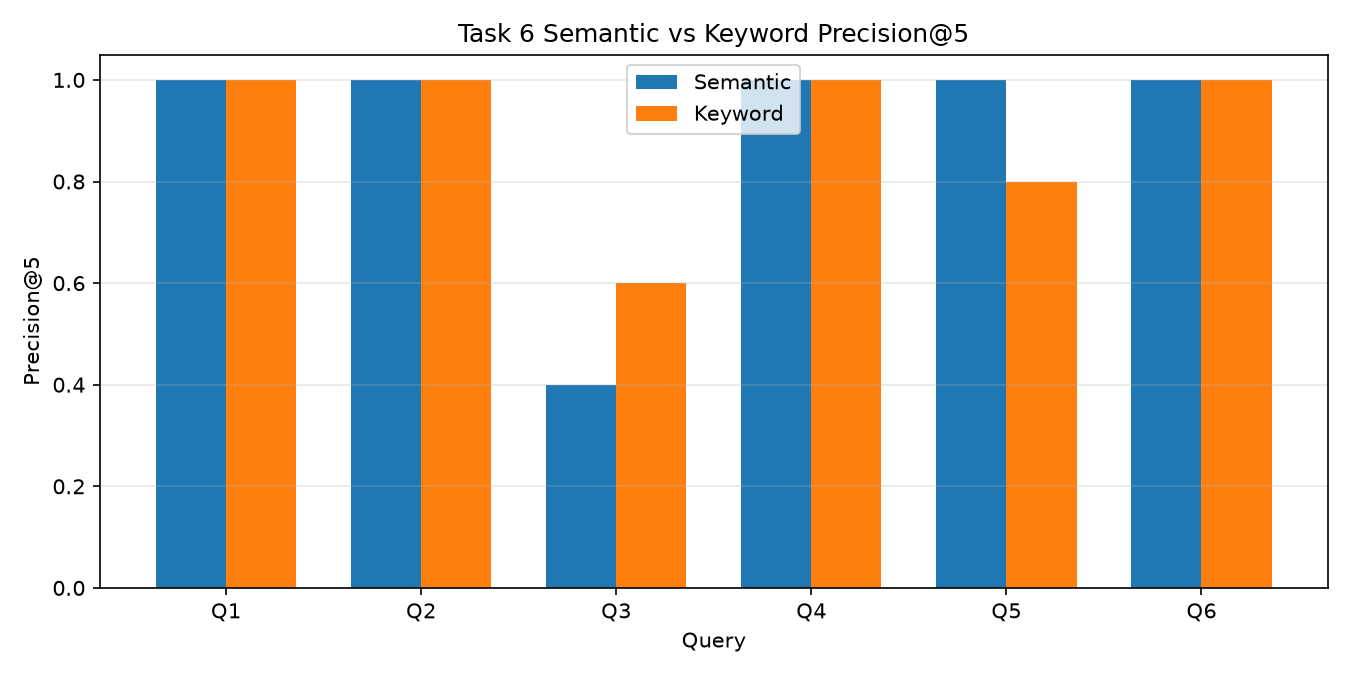

saved: /home/atanas-vitanov/Documents/praksa/ml-interns-mk-2026/interns/atanas/week_6/results/plots/task6_precision_comparison.png


In [28]:
display(Image(filename=precision_plot_path))
print("saved:", precision_plot_path)

**Observation:** The comparison table answers the semantic-vs-keyword requirement. Each row reports the query, expected AG News category, semantic precision@5, keyword precision@5, and which method was better for that query. The chart visualizes the same precision@5 comparison so it is easier to see where semantic search, keyword search, or a tie happened.

## Concrete Wins And Interpretation

**Interpretation question: When does semantic search shine, and when does keyword search suffice?**

Semantic search shines when the query describes a concept rather than relying on exact words. In this notebook, the clearest semantic win is `technology company releases new security software`: semantic search got **P@5 = 1.0**, while keyword search got **P@5 = 0.8** because keyword search was distracted by exact words like `company` and `releases`, returning one Business article about AIG press releases.

Keyword search suffices when the query contains strong exact topic words that appear in relevant articles. For example, `new satellite rocket launch space mission` was a tie with **P@5 = 1.0** for both methods because words like `satellite`, `rocket`, `launch`, and `space` directly match Sci/Tech articles. Keyword search was even better for `stock market and company earnings update`, scoring **0.6** vs semantic search's **0.4**, because exact financial terms helped TF-IDF more than the broader embedding similarity.

Overall, both methods averaged **P@5 = 0.9** in this run, so semantic search was not universally better. It is most useful for paraphrased or meaning-based queries, while keyword search is a strong, cheaper baseline when the query has precise terms that appear in the documents.

## Save Final Summary

In [29]:
semantic_mean_precision = float(comparison_df["semantic_precision_at_5"].mean())
keyword_mean_precision = float(comparison_df["keyword_precision_at_5"].mean())

task6_interpretation = 'Semantic search shines on meaning-based queries such as technology company releases new security software, where it reached P@5=1.0 versus keyword P@5=0.8. Keyword search is sufficient or better when exact topical words are present, as shown by new satellite rocket launch space mission tying at P@5=1.0 and stock market and company earnings update favoring keyword search at 0.6 vs 0.4. Both methods averaged P@5=0.9, so semantic search is not universally better; it is strongest for paraphrase and concept matching, while keyword search is a cheap strong baseline for precise lexical queries.'

index_summary.update(
    {
        "query_count": int(len(query_specs)),
        "keyword_fit_time_seconds": float(keyword_fit_time_seconds),
        "semantic_mean_precision_at_5": semantic_mean_precision,
        "keyword_mean_precision_at_5": keyword_mean_precision,
        "precision_plot": "task6_precision_comparison.png",
        "main_result": "Semantic and keyword search were compared with precision@5 over manually labeled AG News query intents.",
        "interpretation": task6_interpretation,
    }
)

index_summary

{'task': 'Task 6 - Semantic Search with FAISS',
 'dataset': 'Preprocessed AG News',
 'split': 'test',
 'corpus_sample_size': None,
 'corpus_size': 7588,
 'model_name': 'sentence-transformers/all-MiniLM-L6-v2',
 'embedding_dimension': 384,
 'embedding_time_seconds': 184.51012444496155,
 'index_type': 'faiss.IndexFlatIP',
 'index_build_time_seconds': 0.0038976669311523438,
 'index_memory_bytes': 11655168,
 'index_memory_mb': 11.115234375,
 'normalization': 'L2 normalized vectors so inner product equals cosine similarity.',
 'top_k': 5,
 'seed': 42,
 'query_count': 6,
 'keyword_fit_time_seconds': 0.3885612487792969,
 'semantic_mean_precision_at_5': 0.9,
 'keyword_mean_precision_at_5': 0.9,
 'precision_plot': 'task6_precision_comparison.png',
 'main_result': 'Semantic and keyword search were compared with precision@5 over manually labeled AG News query intents.',
 'interpretation': 'Semantic search shines on meaning-based queries such as technology company releases new security software, w

In [30]:
save_json(
    data=index_summary,
    output_path=METADATA_DIR / "task6_index_summary.json",
)

## Final Answer

Task 6 builds an exact FAISS `IndexFlatIP` over normalized MiniLM sentence embeddings and compares it against a TF-IDF keyword baseline on the same AG News corpus and queries. In this run, both methods averaged **P@5 = 0.9**: semantic search clearly helped on `technology company releases new security software`, while keyword search was competitive or better on queries with exact topical words such as `new satellite rocket launch space mission` and `stock market and company earnings update`. The saved comparison table, query examples, and precision chart show that semantic search is best for meaning-based queries, while keyword search remains a strong baseline for precise lexical queries.